In [1]:
import os
import time
import json
import yaml
import shutil
import warnings
import numpy as np
import pandas as pd

from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

In [2]:
import torch

print("PyTorch Version :", torch.__version__)
print("CUDA Available  :", torch.cuda.is_available())
print("GPU Count       :", torch.cuda.device_count())

if torch.cuda.is_available():
    print("GPU Name        :", torch.cuda.get_device_name(0))

PyTorch Version : 2.8.0+cu129
CUDA Available  : True
GPU Count       : 1
GPU Name        : NVIDIA GeForce RTX 2080 SUPER


In [3]:
DATA_YAML = "/home/f15c/H/Plastic_Shampoo_Bottle_Dataset/data.yaml"

CLASS_NAMES = ['adhesion_marg', 'adhesion_unacc', 'dent_marg', 'dent_unacc', 'pob_marg', 'pob_unacc', 'scuff_marg', 'scuff_unacc', 'tear_marg', 'tear_unacc']

NUM_CLASSES = len(CLASS_NAMES)

print("Classes:", CLASS_NAMES)
print("Number of Classes:", NUM_CLASSES)

Classes: ['adhesion_marg', 'adhesion_unacc', 'dent_marg', 'dent_unacc', 'pob_marg', 'pob_unacc', 'scuff_marg', 'scuff_unacc', 'tear_marg', 'tear_unacc']
Number of Classes: 10


In [4]:
IMG_SIZE = 640

EPOCHS = 100

BATCH_SIZE = 16

WORKERS = 4

DEVICE = 0

SEED = 42

In [5]:
models_info = {
    "YOLOv8n": {
        "weights": "yolov8n.pt",
        "params_m": 3.2,
        "gflops": 8.7
    },

    "YOLOv9-C": {
        "weights": "yolov9-c.pt",
        "params_m": 51.0,
        "gflops": 238.9
    },

    "YOLOv10n": {
        "weights": "yolov10n.pt",
        "params_m": 2.7,
        "gflops": 8.4
    },

    "YOLO11n": {
        "weights": "yolo11n.pt",
        "params_m": 2.6,
        "gflops": 6.5
    },

    "YOLOX-Nano": {
        "weights": "yolox_nano.pth",
        "params_m": 0.9,
        "gflops": 1.1
    }
}

pd.DataFrame(models_info).T

,weights,params_m,gflops
YOLOv8n,yolov8n.pt,3.2,8.7
YOLOv9-C,yolov9-c.pt,51.0,238.9
YOLOv10n,yolov10n.pt,2.7,8.4
YOLO11n,yolo11n.pt,2.6,6.5
YOLOX-Nano,yolox_nano.pth,0.9,1.1


In [6]:
ROOT_DIR = "Model_Comparison"

TRAIN_DIR = os.path.join(ROOT_DIR, "Training")
RESULTS_DIR = os.path.join(ROOT_DIR, "Results")
PLOTS_DIR = os.path.join(ROOT_DIR, "Plots")
TABLES_DIR = os.path.join(ROOT_DIR, "Tables")

for path in [
    ROOT_DIR,
    TRAIN_DIR,
    RESULTS_DIR,
    PLOTS_DIR,
    TABLES_DIR
]:
    os.makedirs(path, exist_ok=True)

print("Folders Created Successfully")

Folders Created Successfully


In [7]:
comparison_df = pd.DataFrame(columns=[
    "Model",
    "Parameters(M)",
    "GFLOPs",
    "Training_Time(min)",
    "Precision",
    "Recall",
    "F1",
    "mAP50",
    "mAP50-95",
    "FPS"
])

comparison_df

,Model,Parameters(M),GFLOPs,Training_Time(min),Precision,Recall,F1,mAP50,mAP50-95,FPS


In [8]:
def calculate_f1(precision, recall):

    if precision + recall == 0:
        return 0

    return 2 * precision * recall / (precision + recall)

In [9]:
def save_comparison_table(df):

    csv_path = os.path.join(
        TABLES_DIR,
        "model_comparison.csv"
    )

    df.to_csv(csv_path, index=False)

    print("Saved:", csv_path)

In [10]:
print("Dataset :", DATA_YAML)
print("Image Size :", IMG_SIZE)
print("Epochs :", EPOCHS)
print("Batch Size :", BATCH_SIZE)

print("\nModels To Compare:")

for model in models_info:
    print(model)

Dataset : /home/f15c/H/Plastic_Shampoo_Bottle_Dataset/data.yaml
Image Size : 640
Epochs : 100
Batch Size : 16

Models To Compare:
YOLOv8n
YOLOv9-C
YOLOv10n
YOLO11n
YOLOX-Nano


In [11]:
from ultralytics import YOLO
import time
import os
import pandas as pd

In [12]:
YOLOV8_MODEL = "yolov8n.pt"

YOLOV8_PROJECT = "YOLO_Experiments"

YOLOV8_RUN_NAME = "YOLOv8n_Plastic_Shampoo_Bottle"

print("Model:", YOLOV8_MODEL)
print("Dataset:", DATA_YAML)
print("Epochs:", EPOCHS)
print("Image Size:", IMG_SIZE)

Model: yolov8n.pt
Dataset: /home/f15c/H/Plastic_Shampoo_Bottle_Dataset/data.yaml
Epochs: 100
Image Size: 640


In [13]:
start_time = time.time()

model_v8 = YOLO(YOLOV8_MODEL)

results_v8 = model_v8.train(
    
    data=DATA_YAML,

    epochs=EPOCHS,

    imgsz=IMG_SIZE,

    batch=BATCH_SIZE,

    workers=WORKERS,

    device=DEVICE,

    project=YOLOV8_PROJECT,

    name=YOLOV8_RUN_NAME,

    verbose=True
)

end_time = time.time()

training_time_v8 = (end_time - start_time) / 60

print(f"\nTraining Time: {training_time_v8:.2f} minutes")

New https://pypi.org/project/ultralytics/8.4.73 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.70 🚀 Python-3.12.11 torch-2.8.0+cu129 CUDA:0 (NVIDIA GeForce RTX 2080 SUPER, 7783MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/f15c/H/Plastic_Shampoo_Bottle_Dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0

In [14]:
training_log_v8 = pd.DataFrame({
    
    "Model":["YOLOv8n"],

    "Training_Time(min)":[training_time_v8]
})

training_log_v8

,Model,Training_Time(min)
0,YOLOv8n,63.216972


In [15]:
YOLOV8_RESULTS_DIR = os.path.join(
    YOLOV8_PROJECT,
    YOLOV8_RUN_NAME
)

print(YOLOV8_RESULTS_DIR)

YOLO_Experiments/YOLOv8n_Plastic_Shampoo_Bottle


results.png


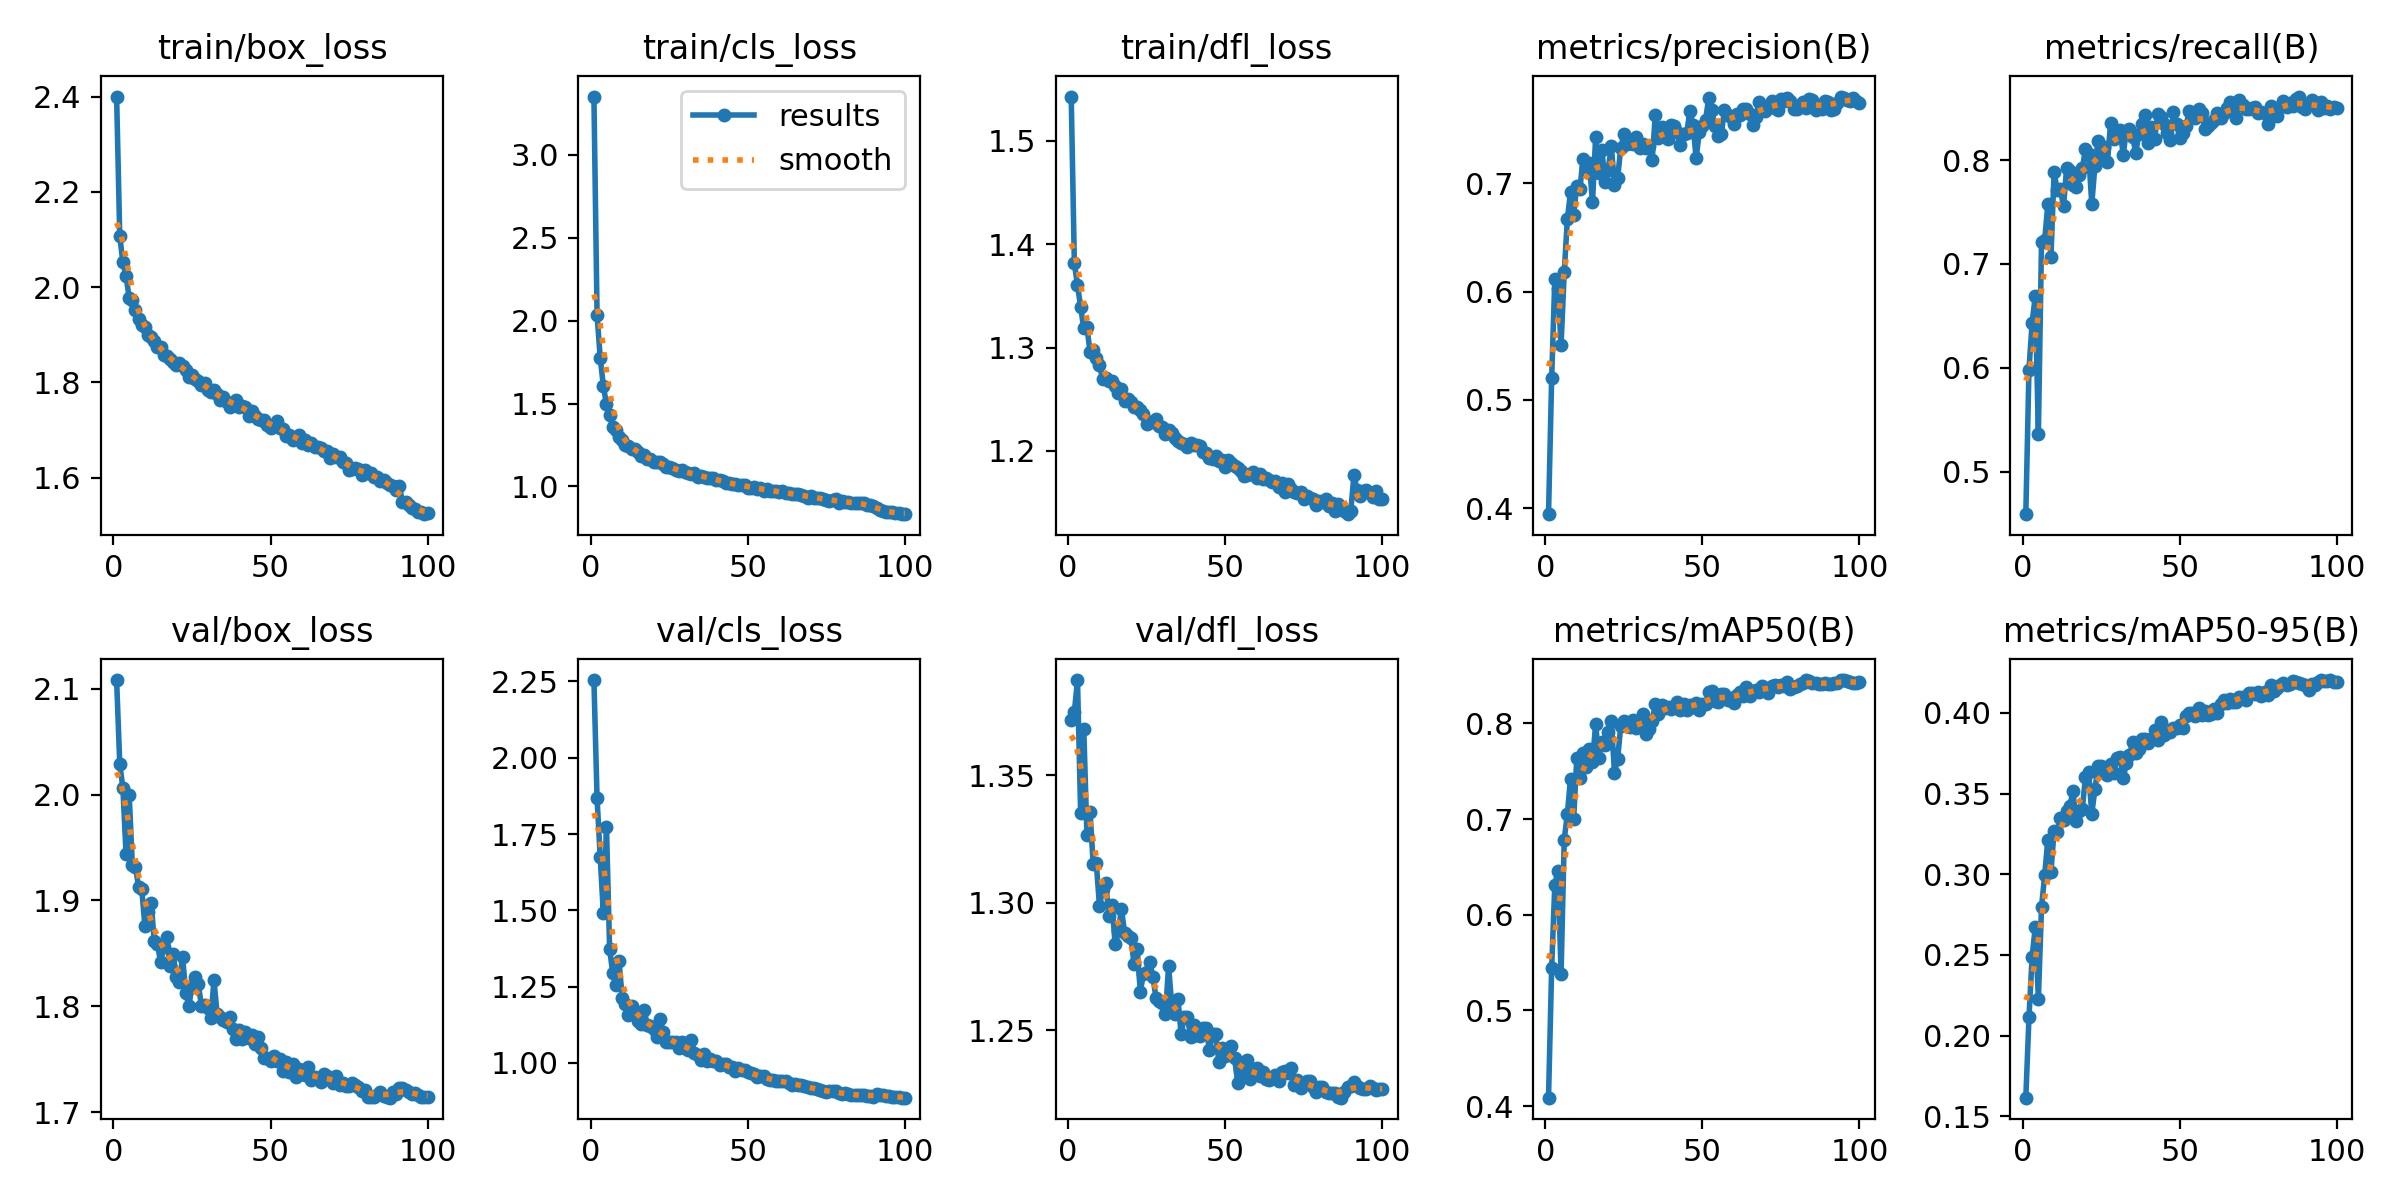

confusion_matrix.png


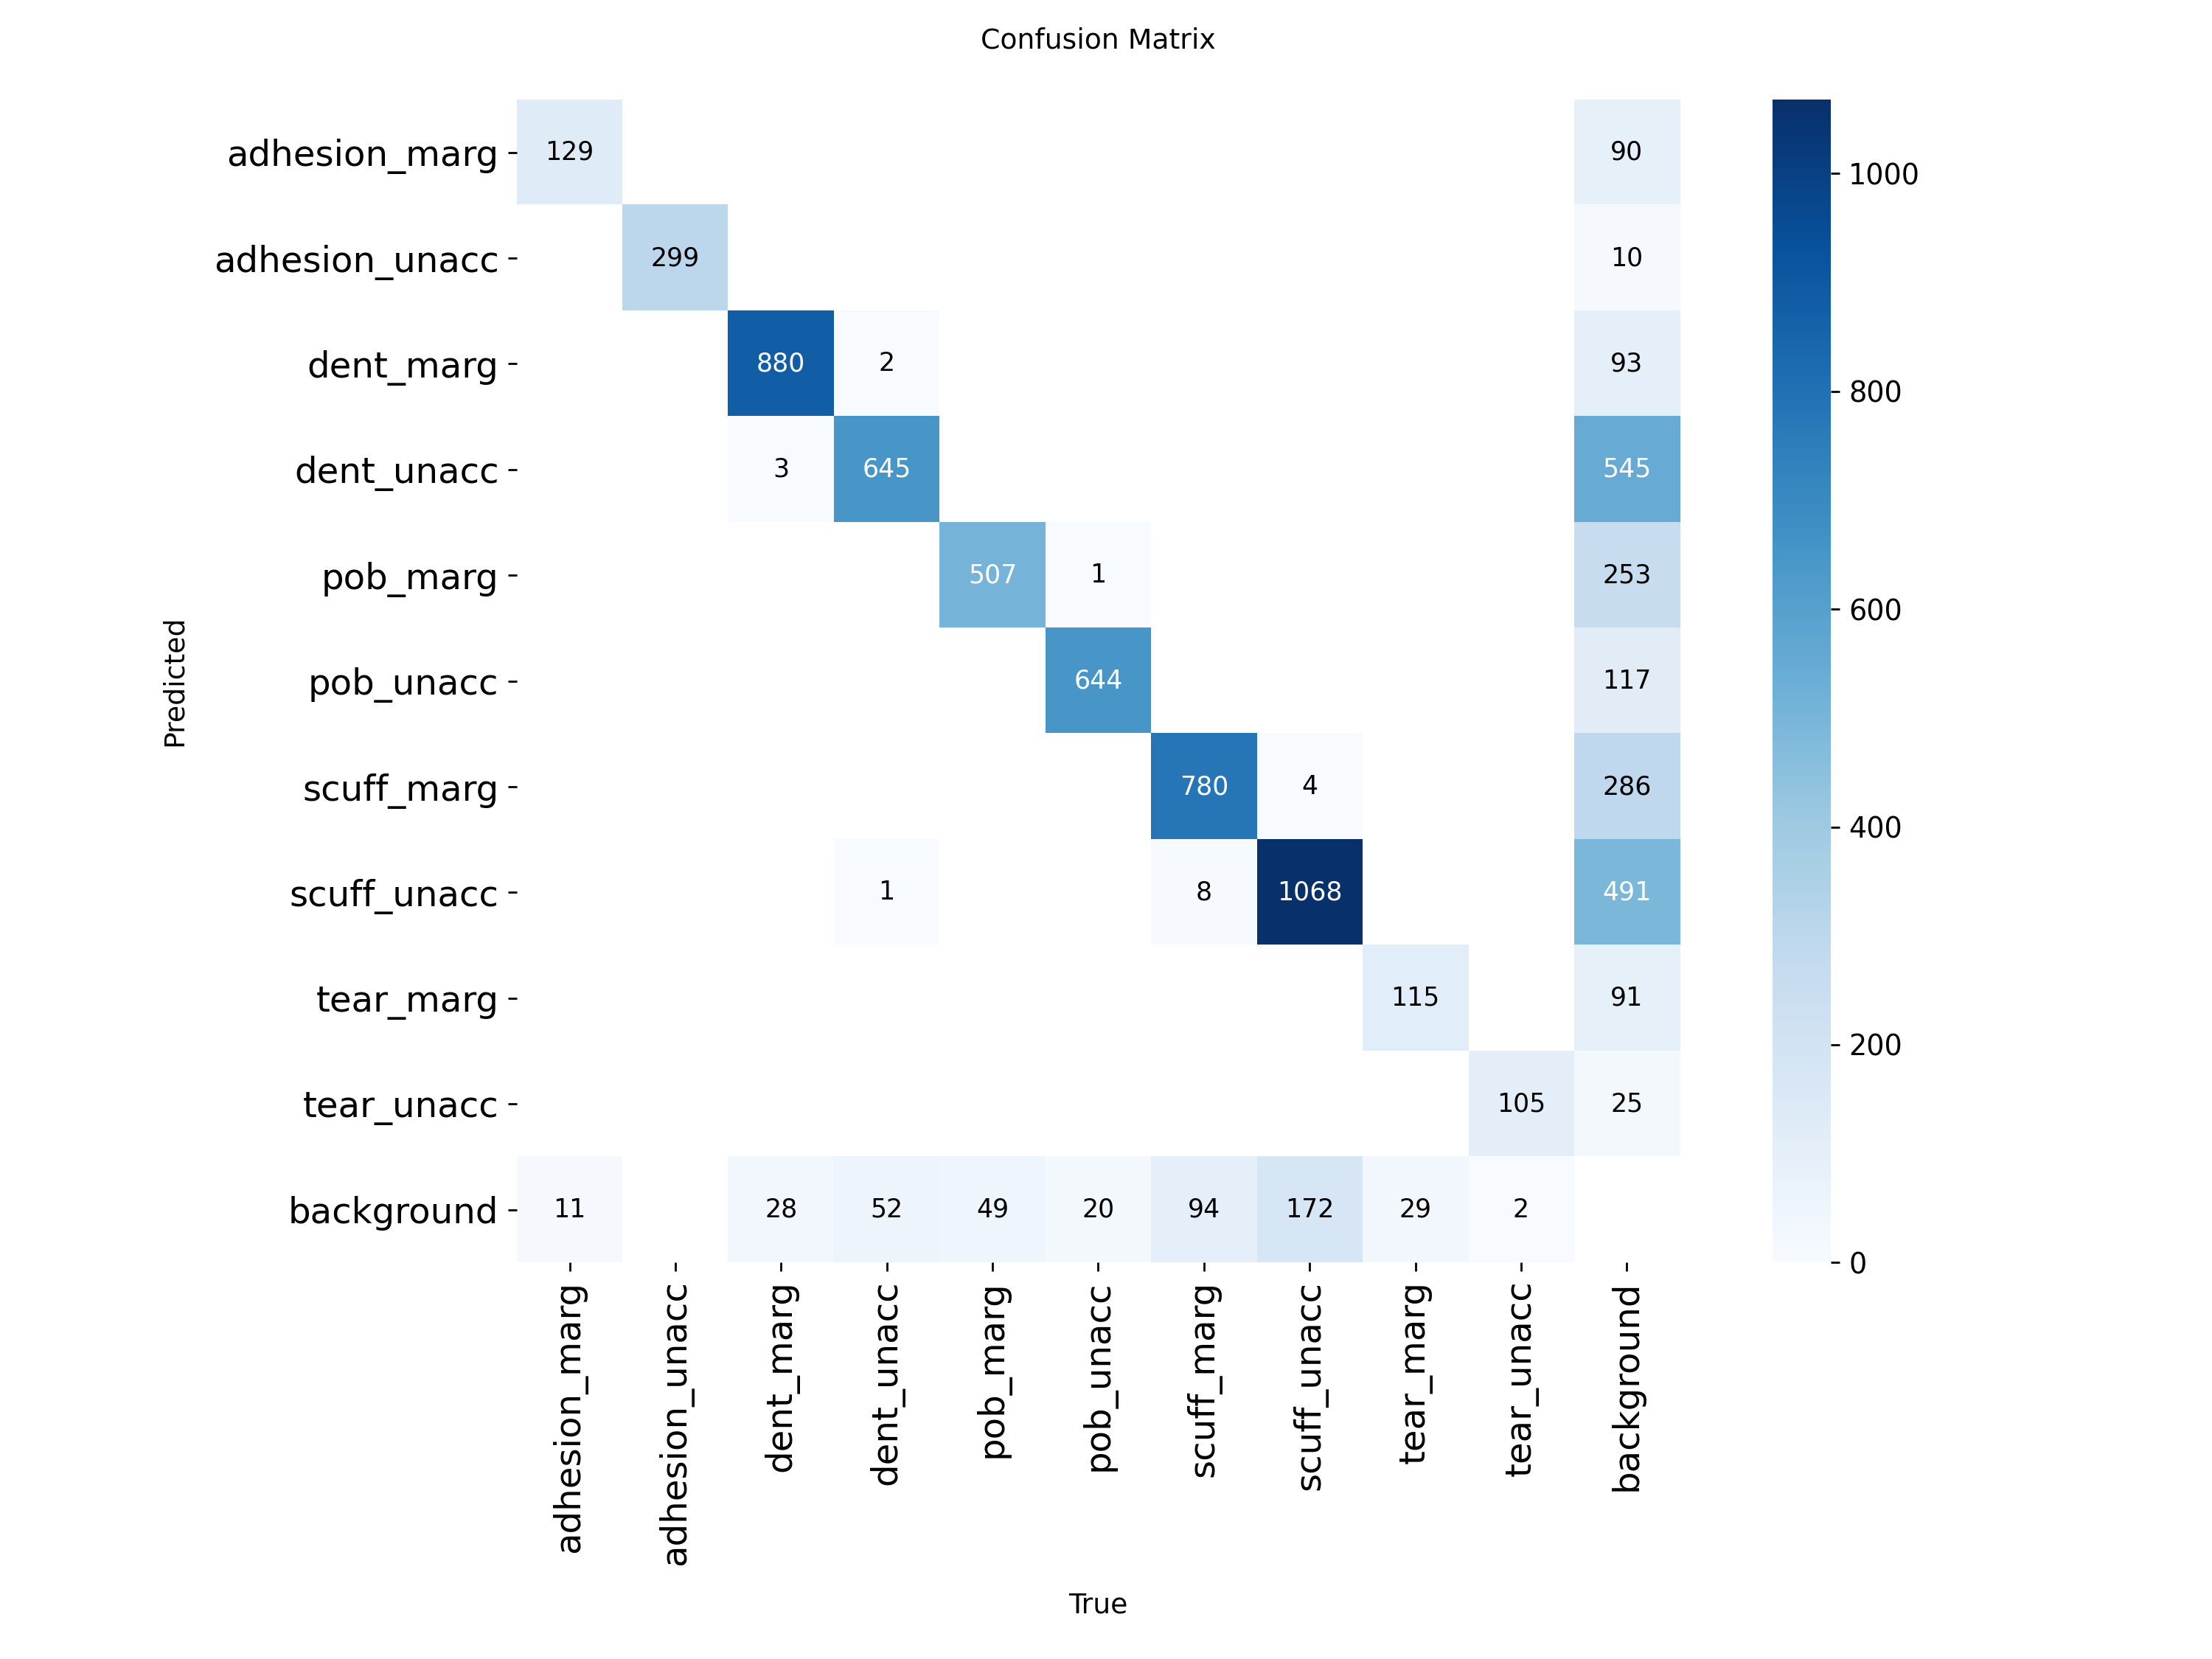

confusion_matrix_normalized.png


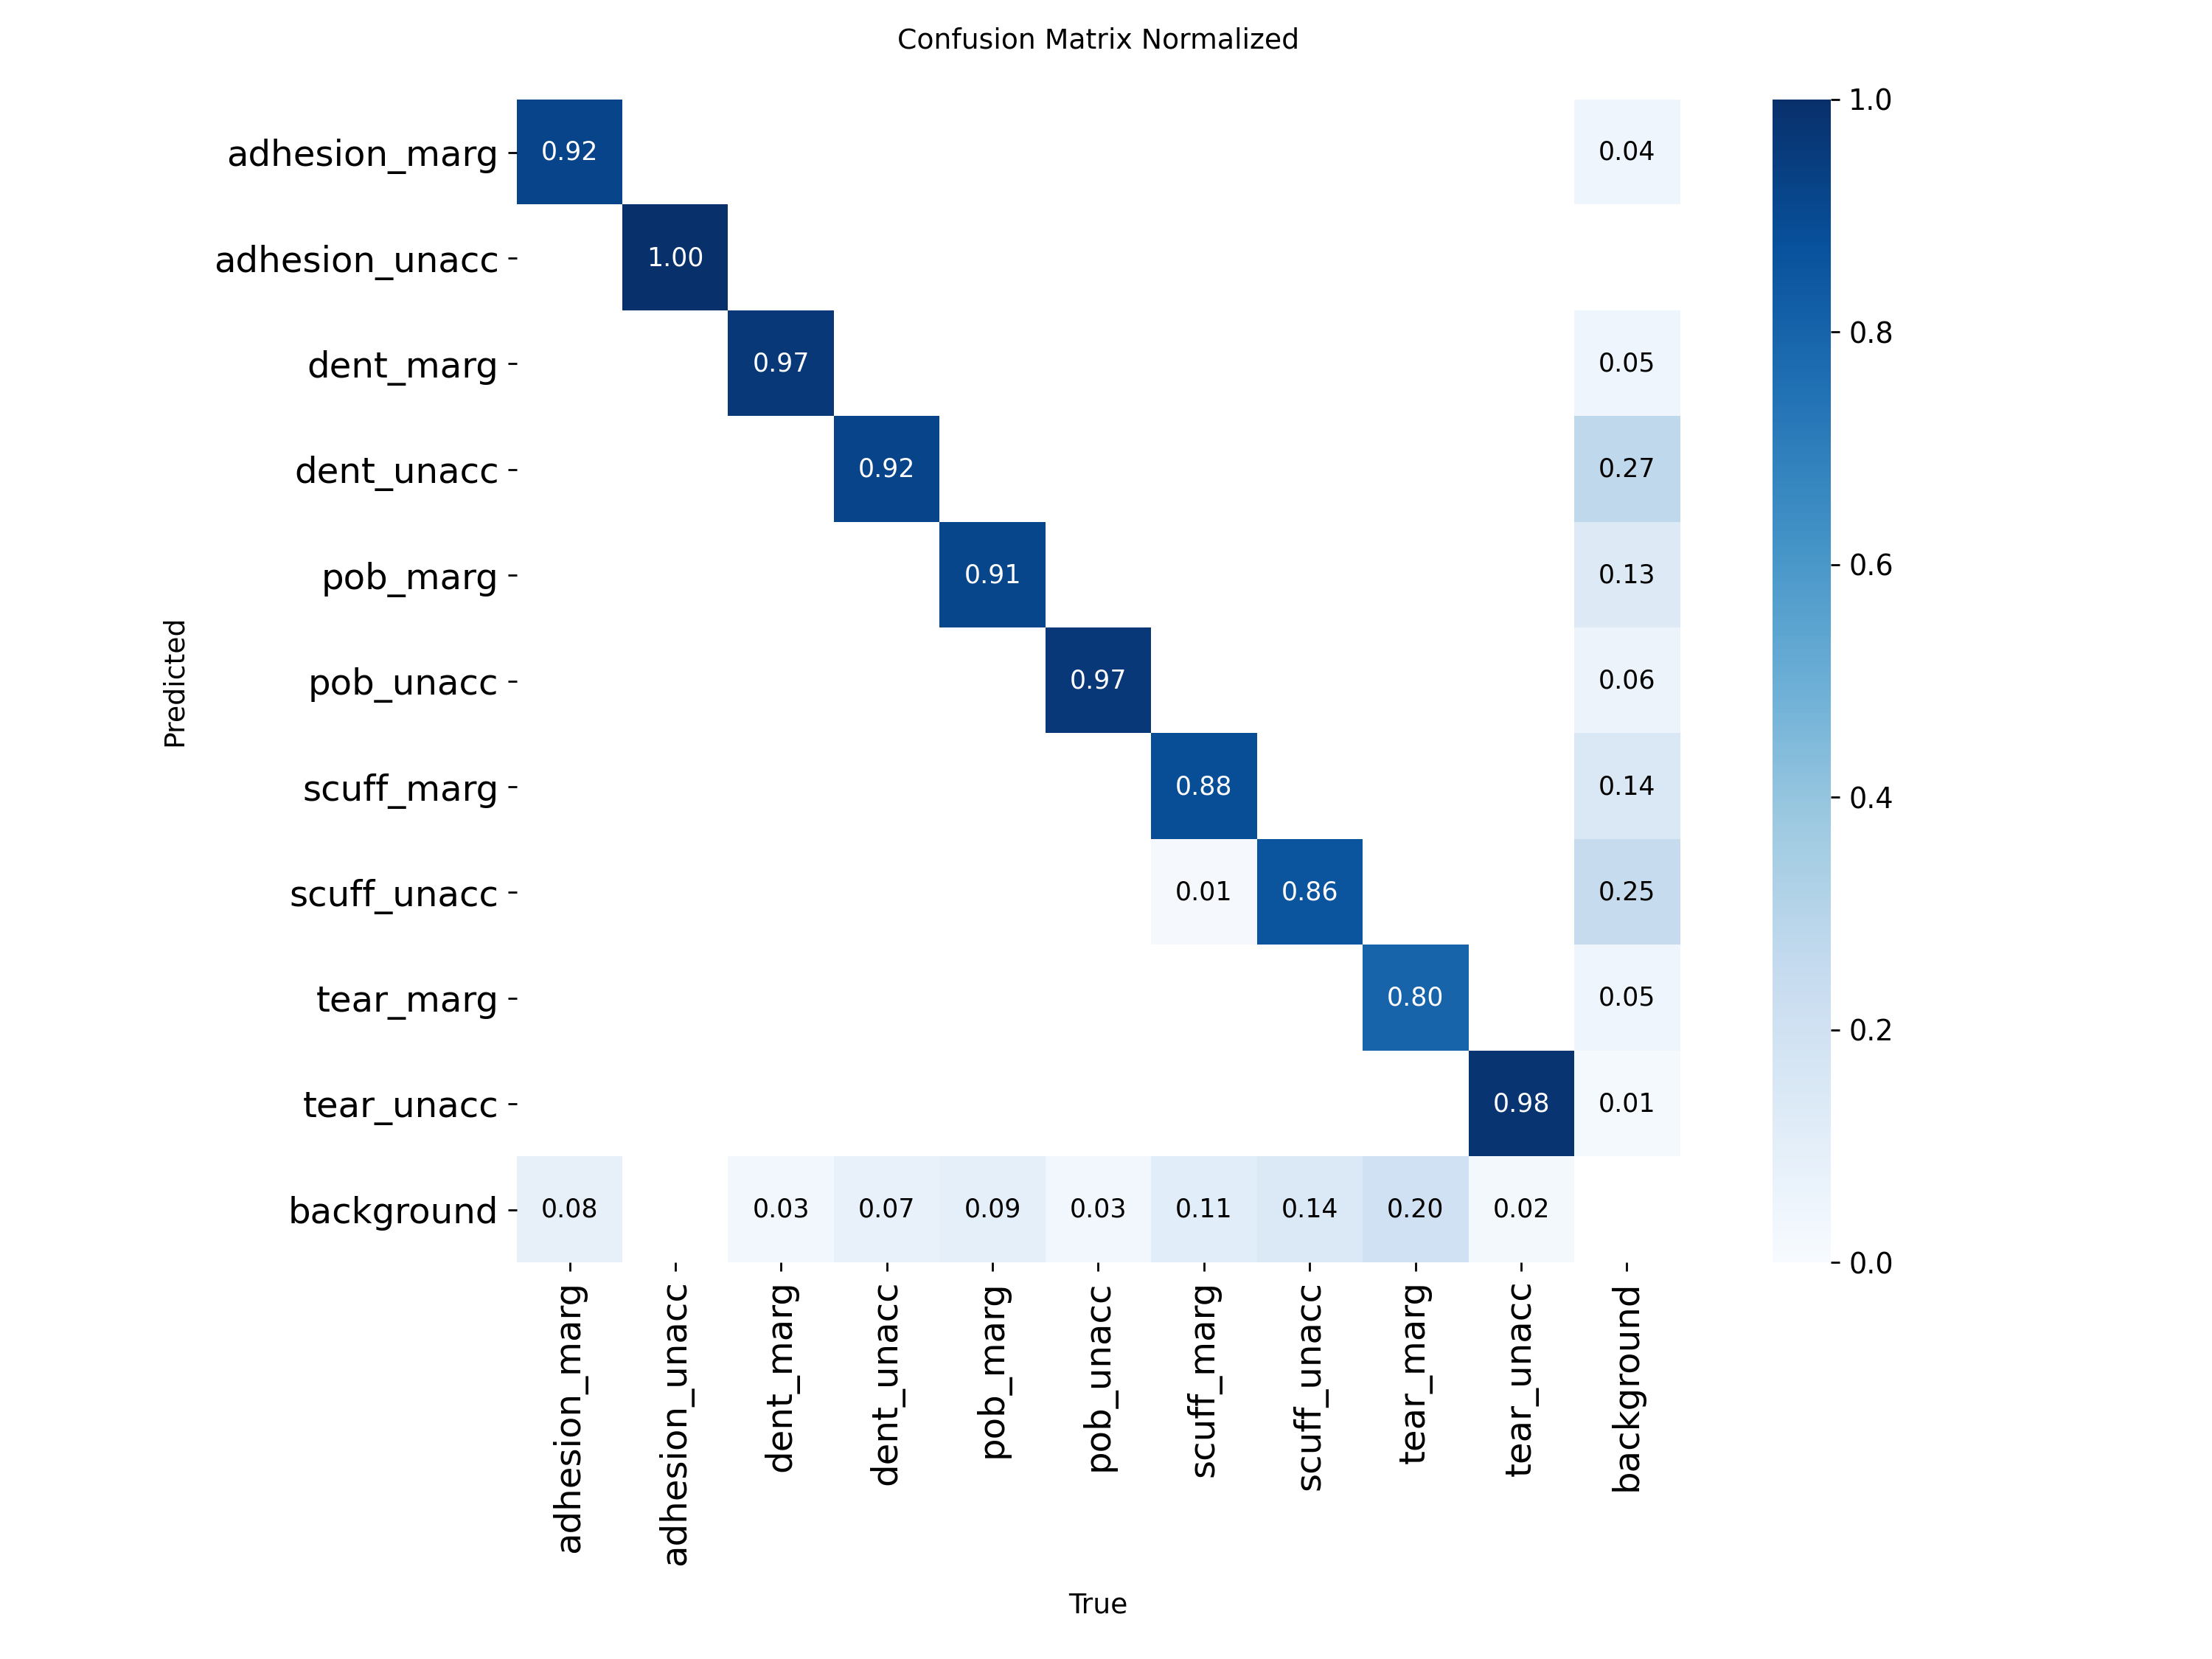

BoxPR_curve.png


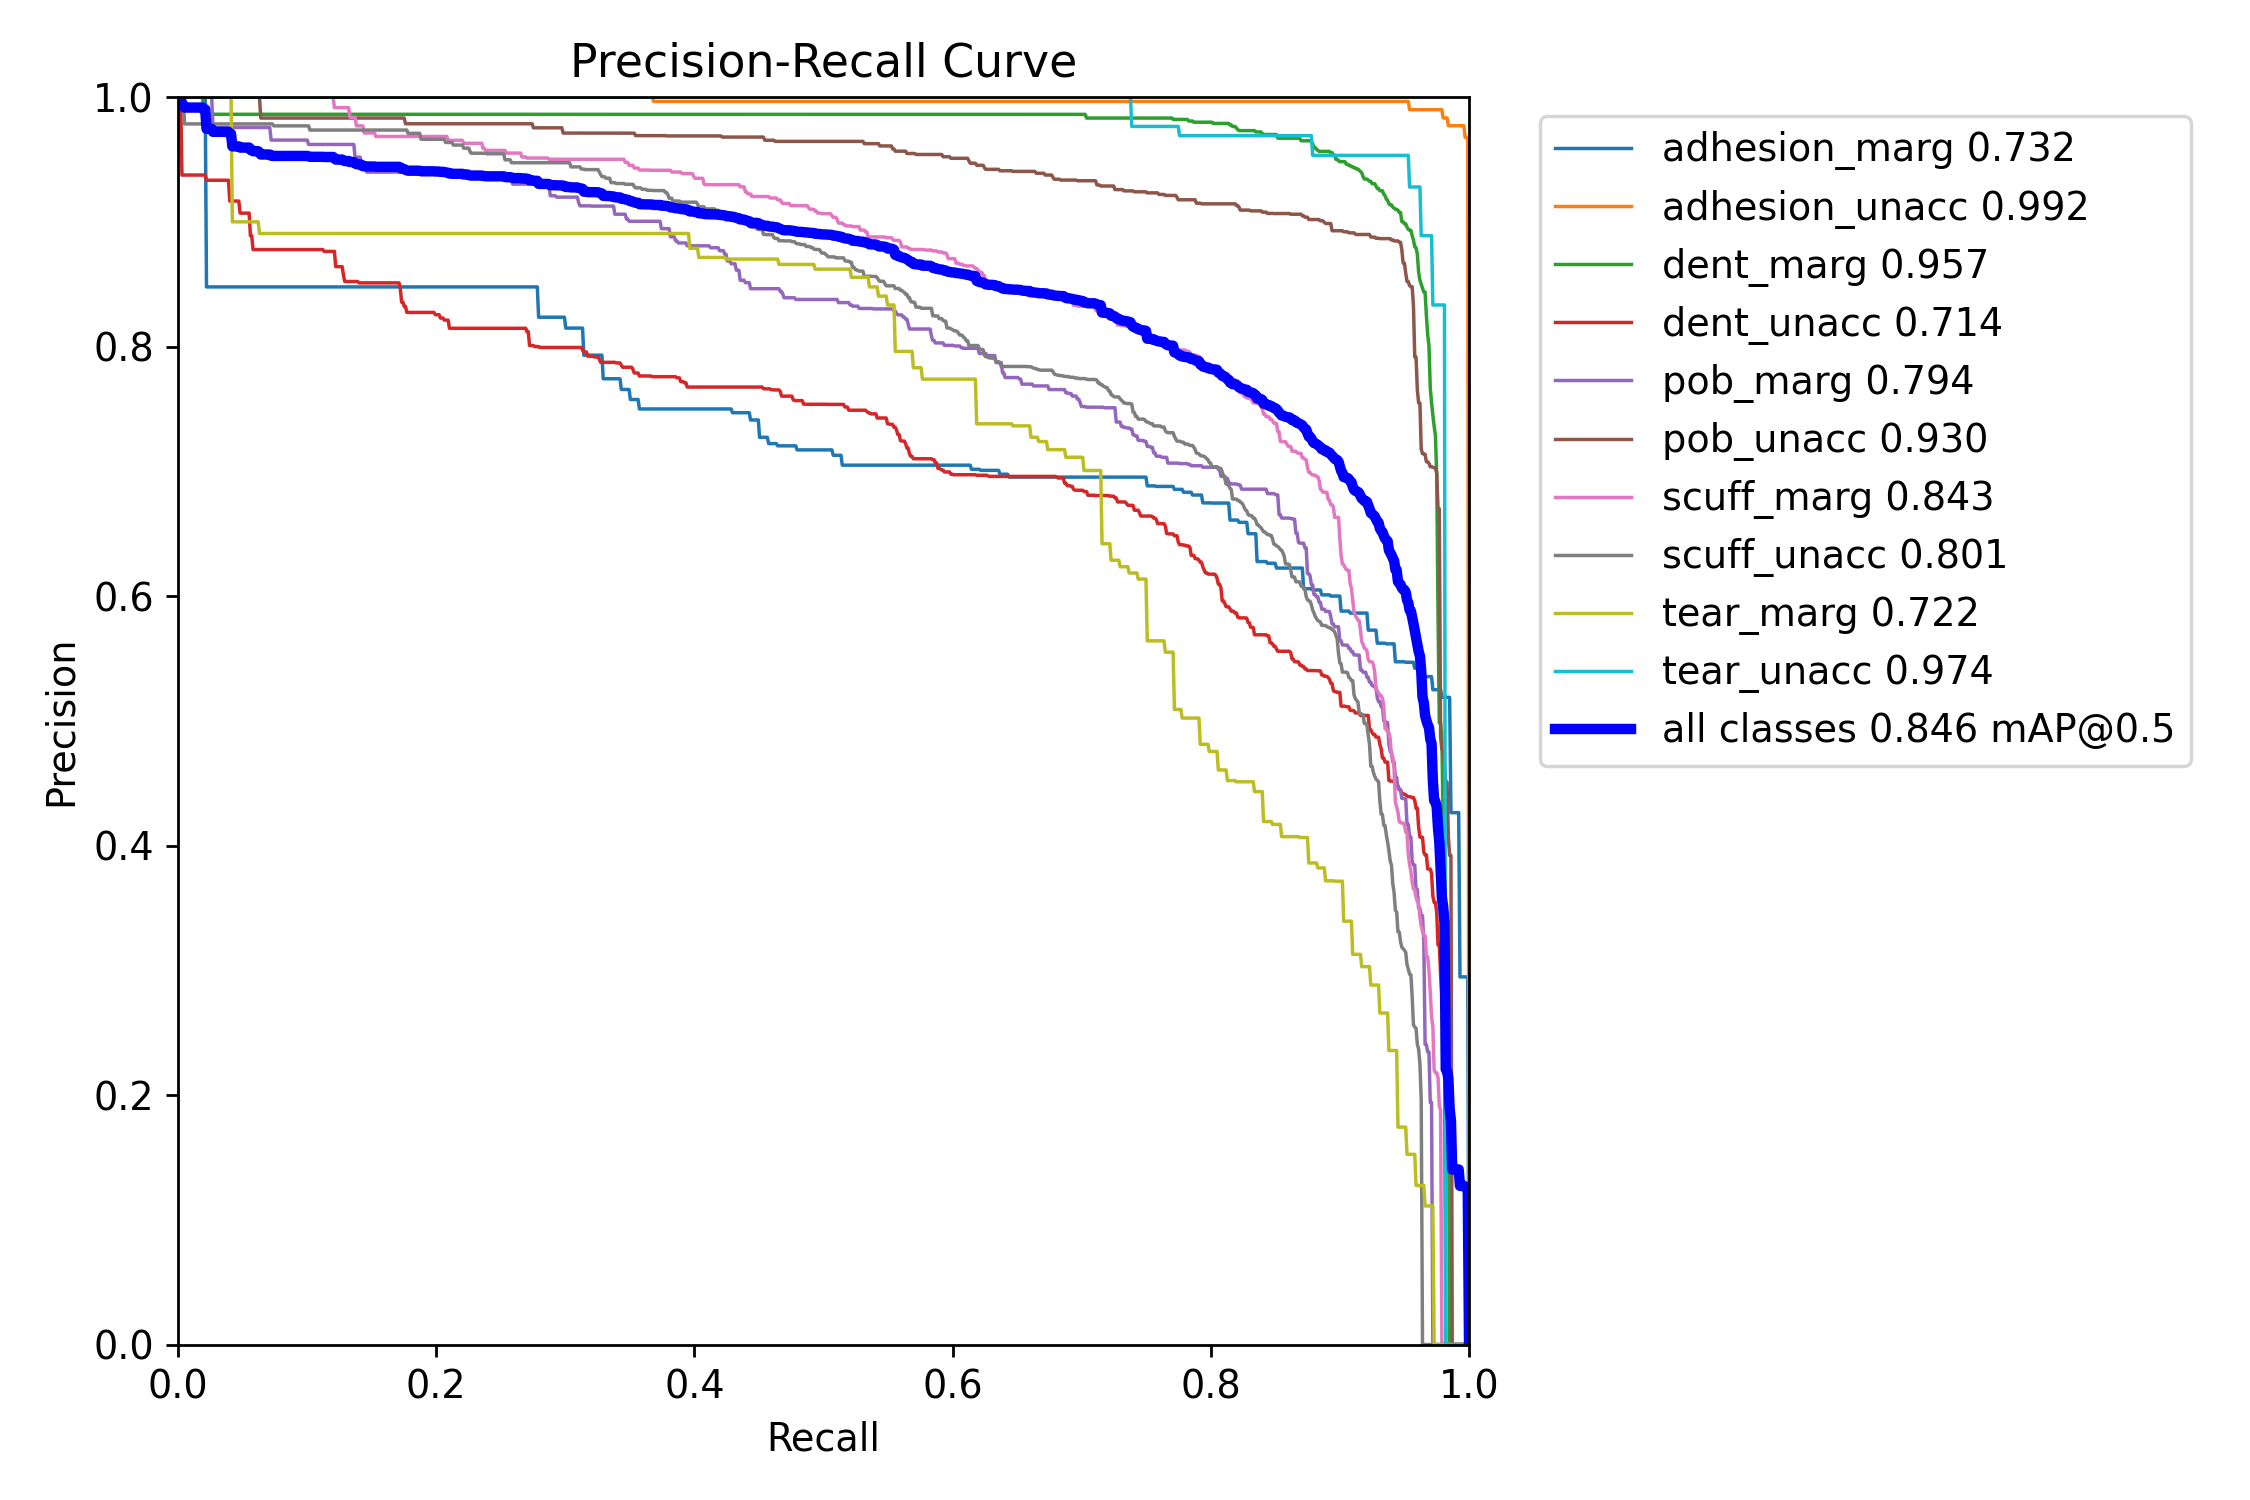

BoxF1_curve.png


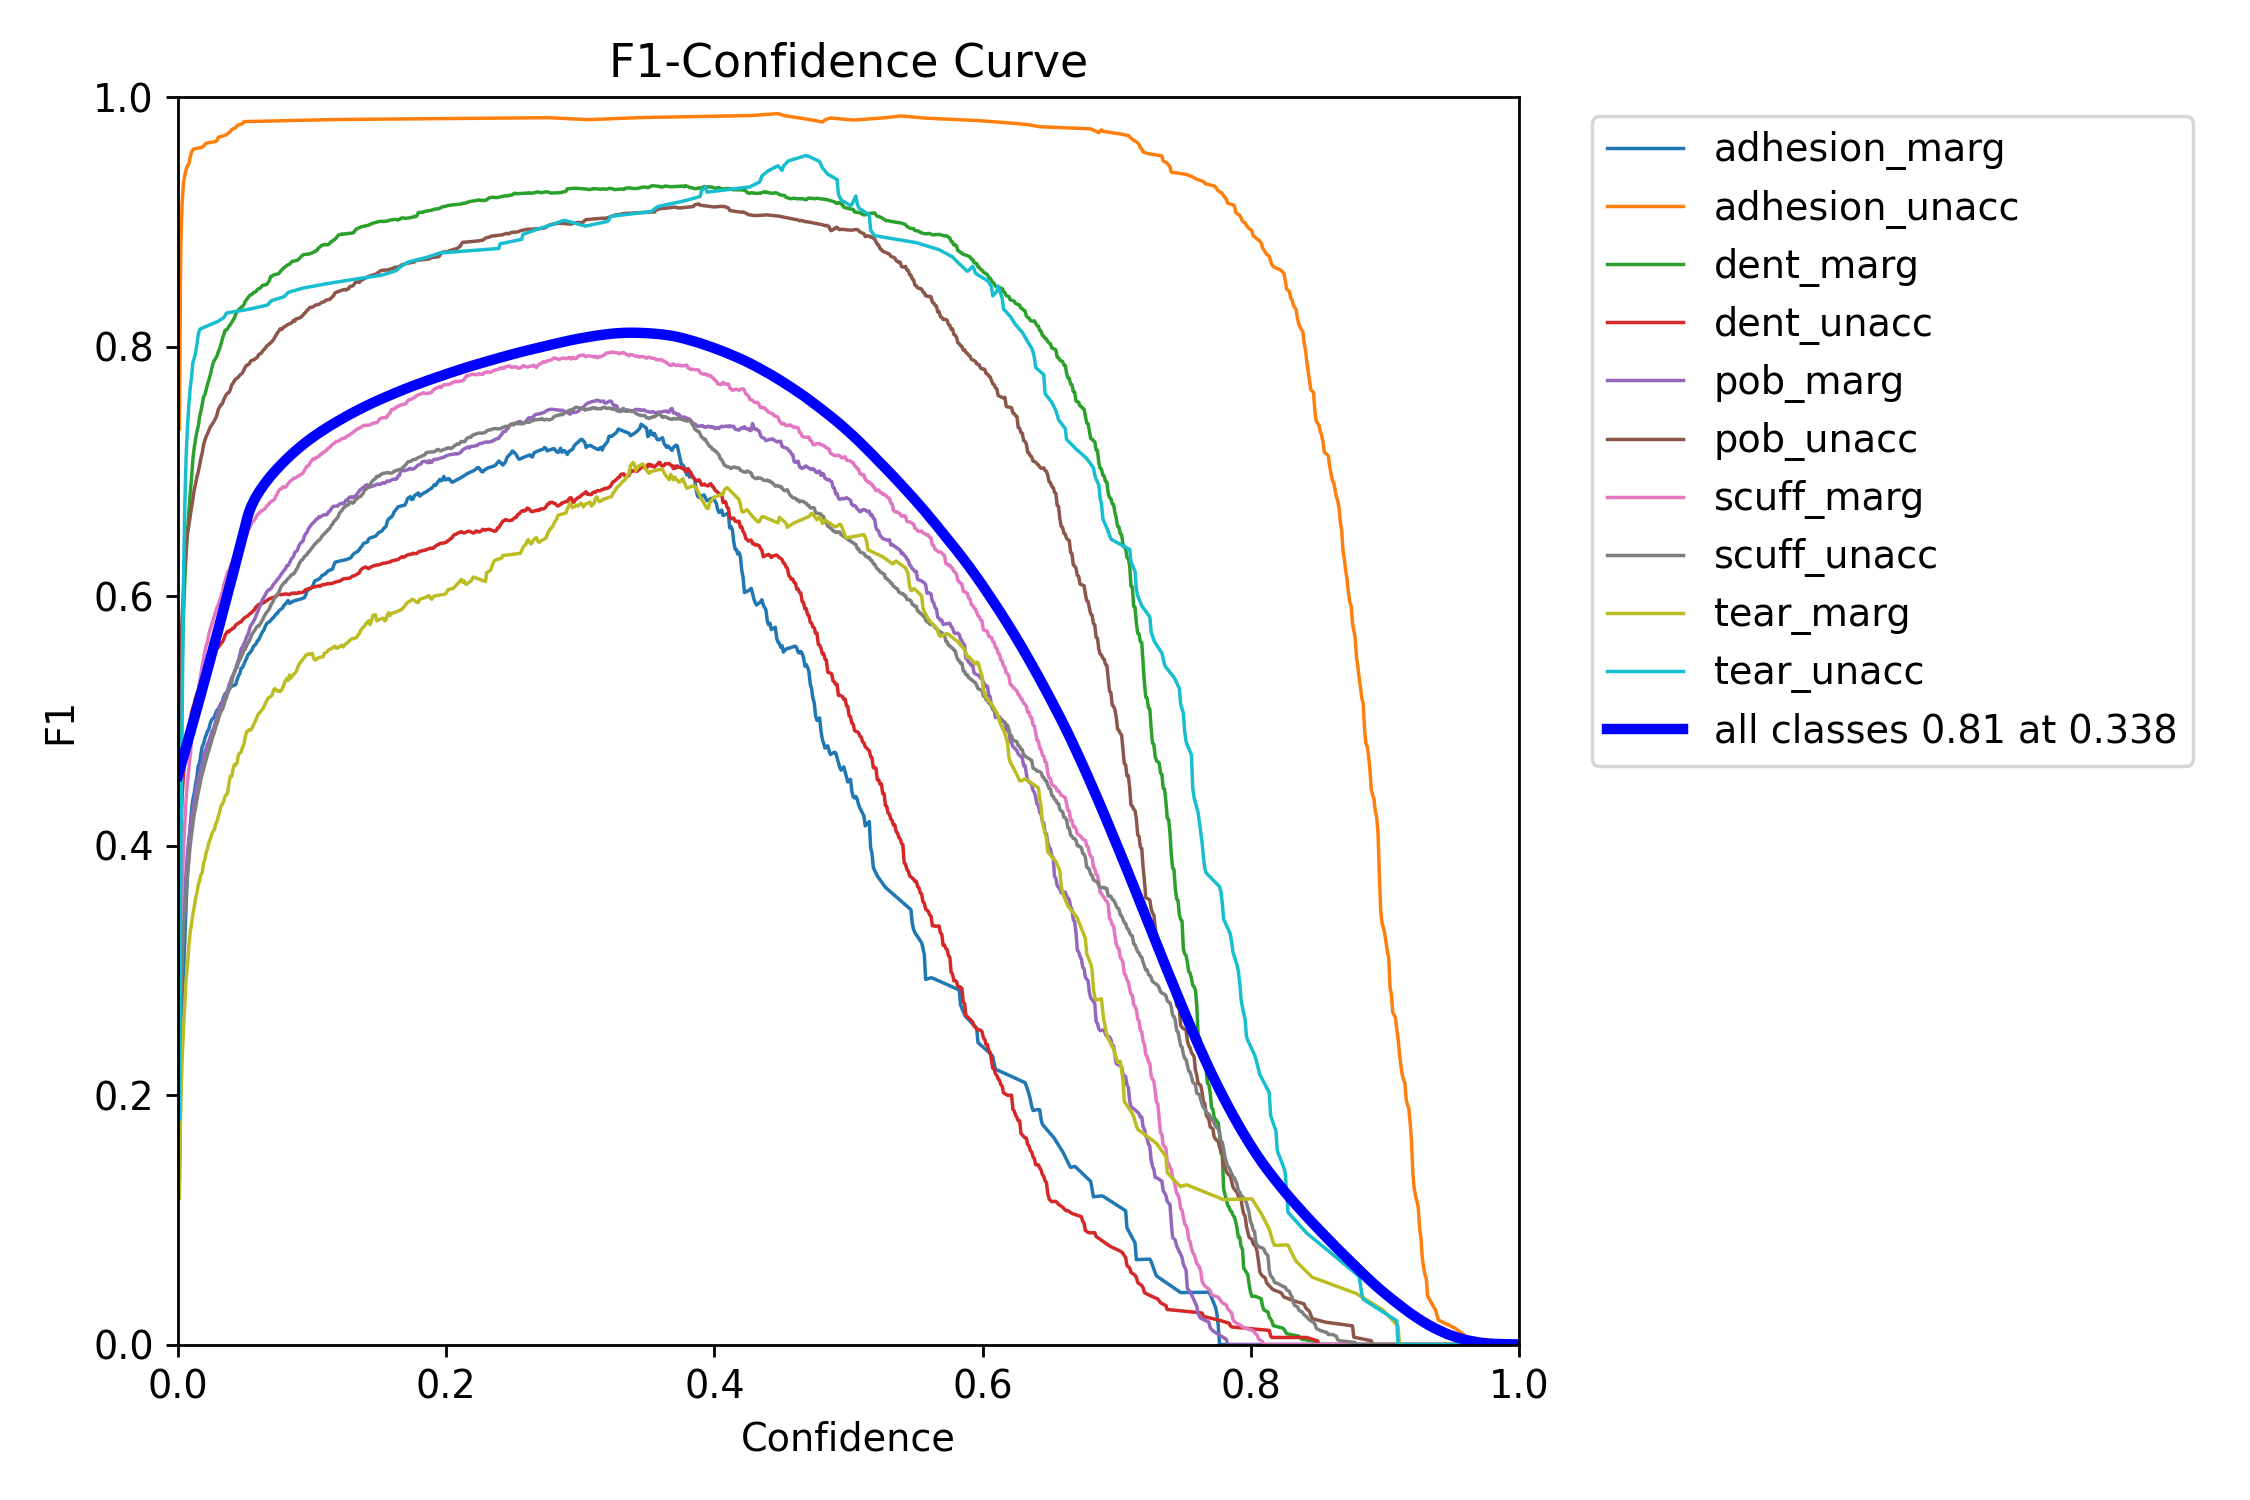

BoxP_curve.png


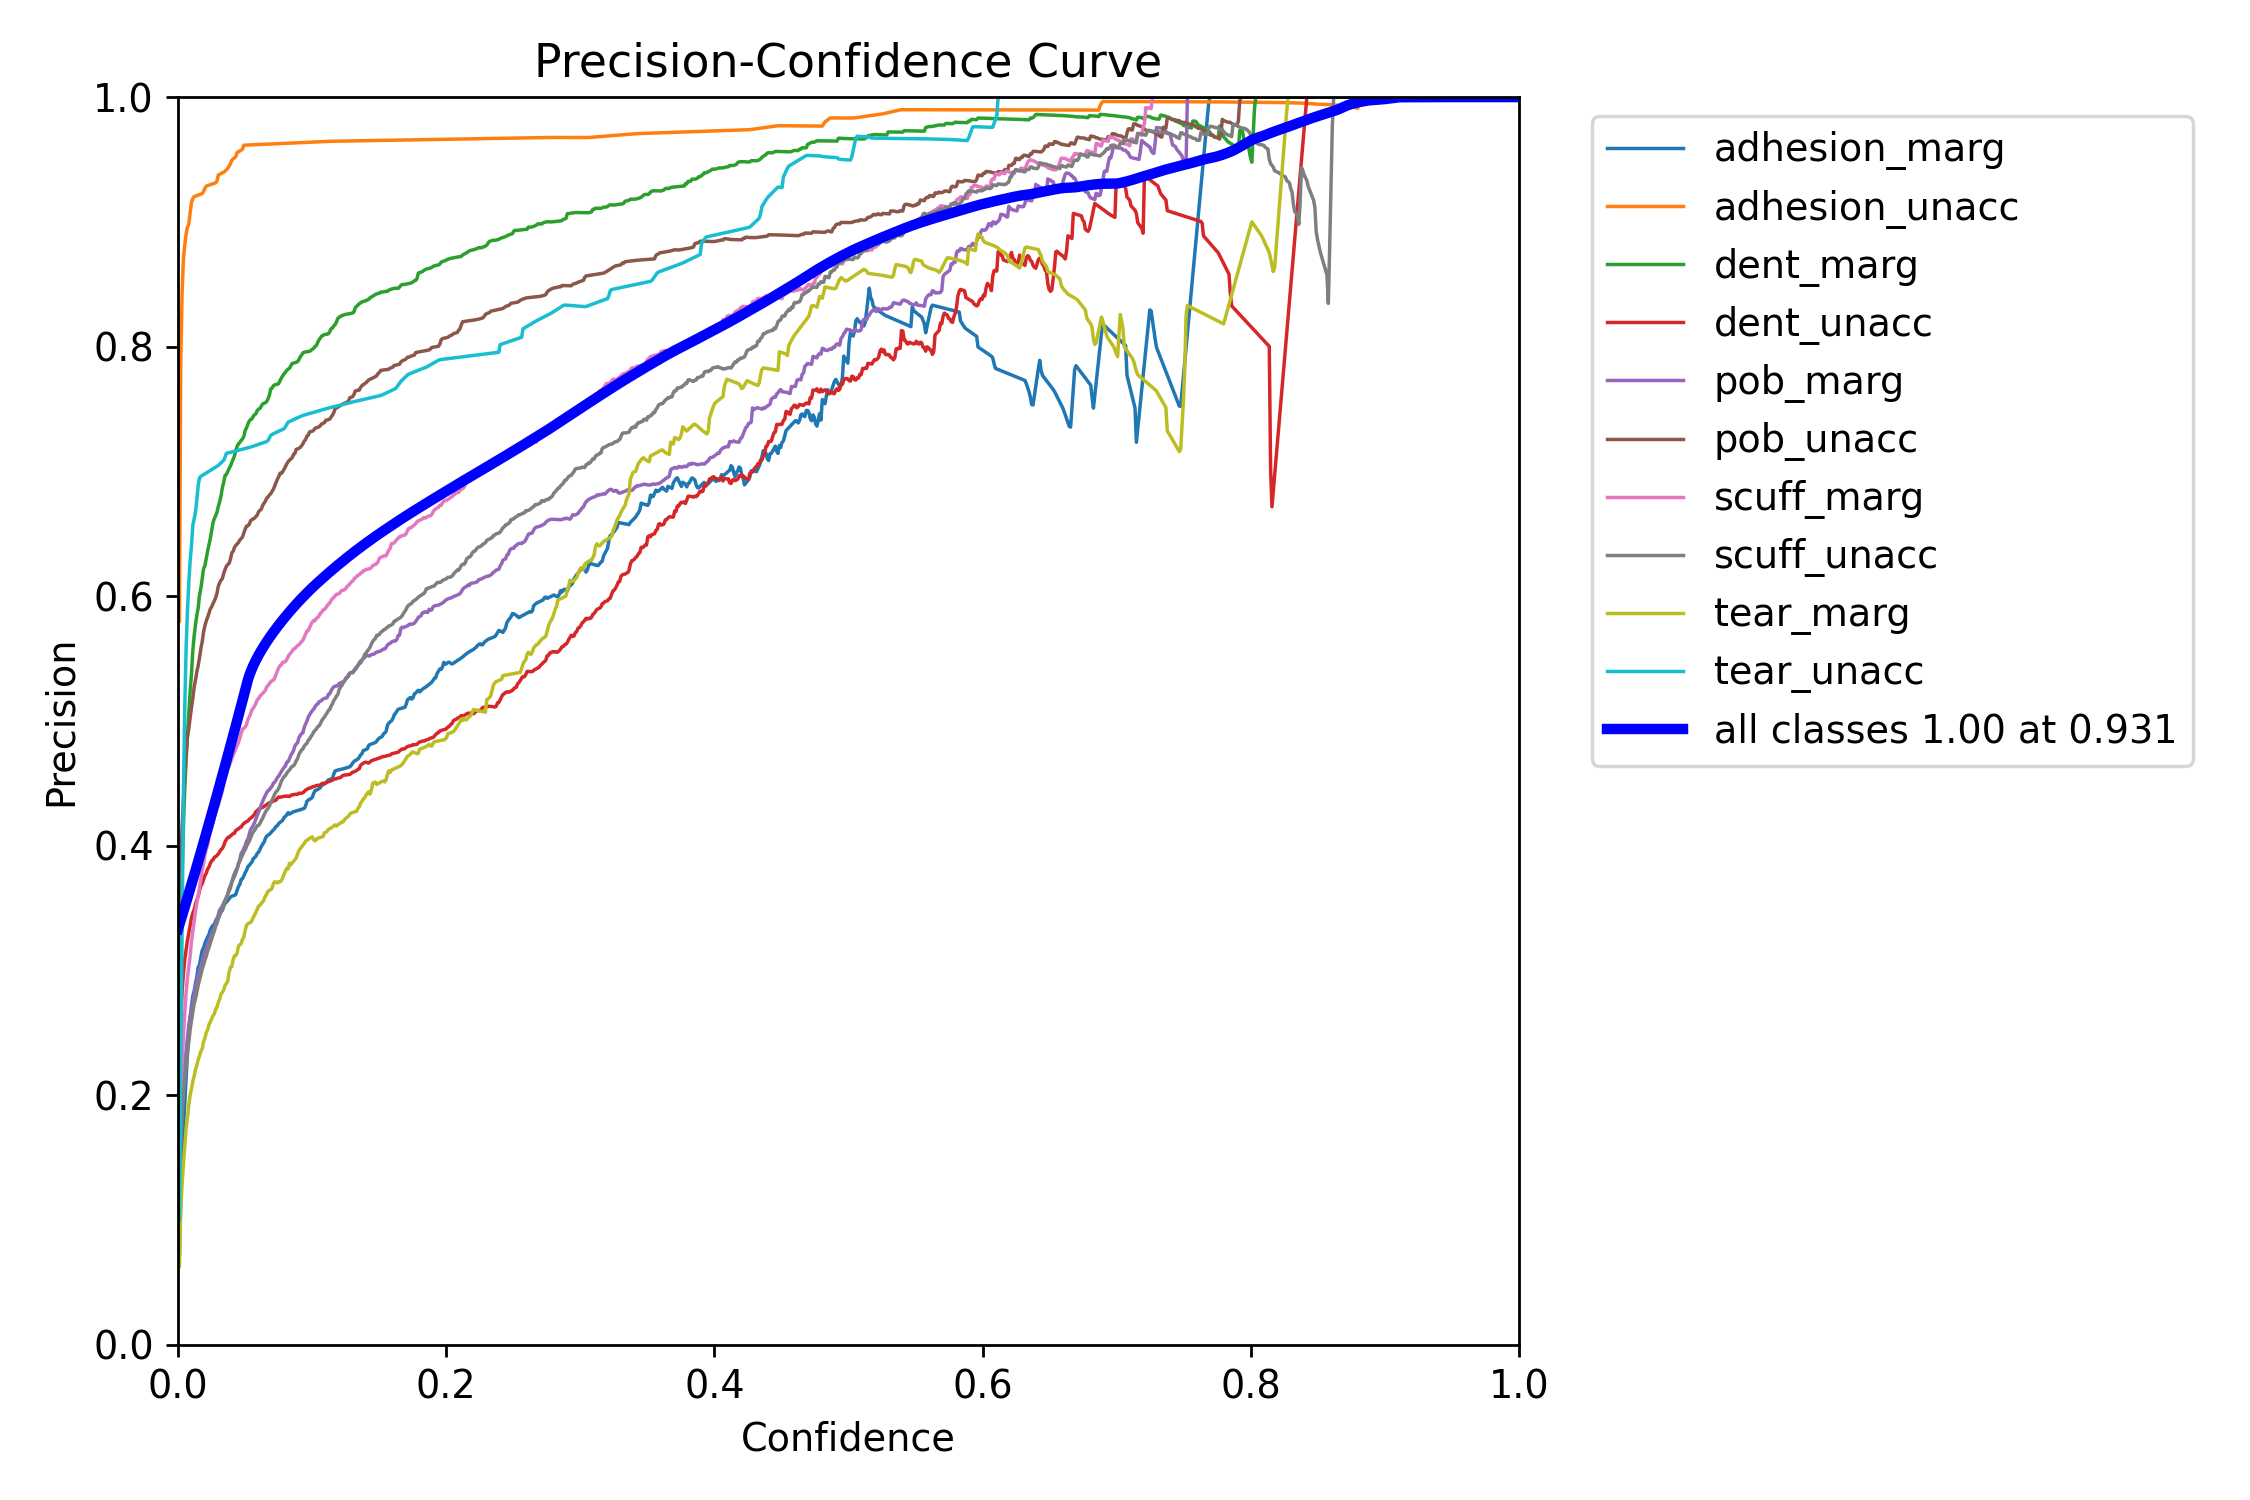

BoxR_curve.png


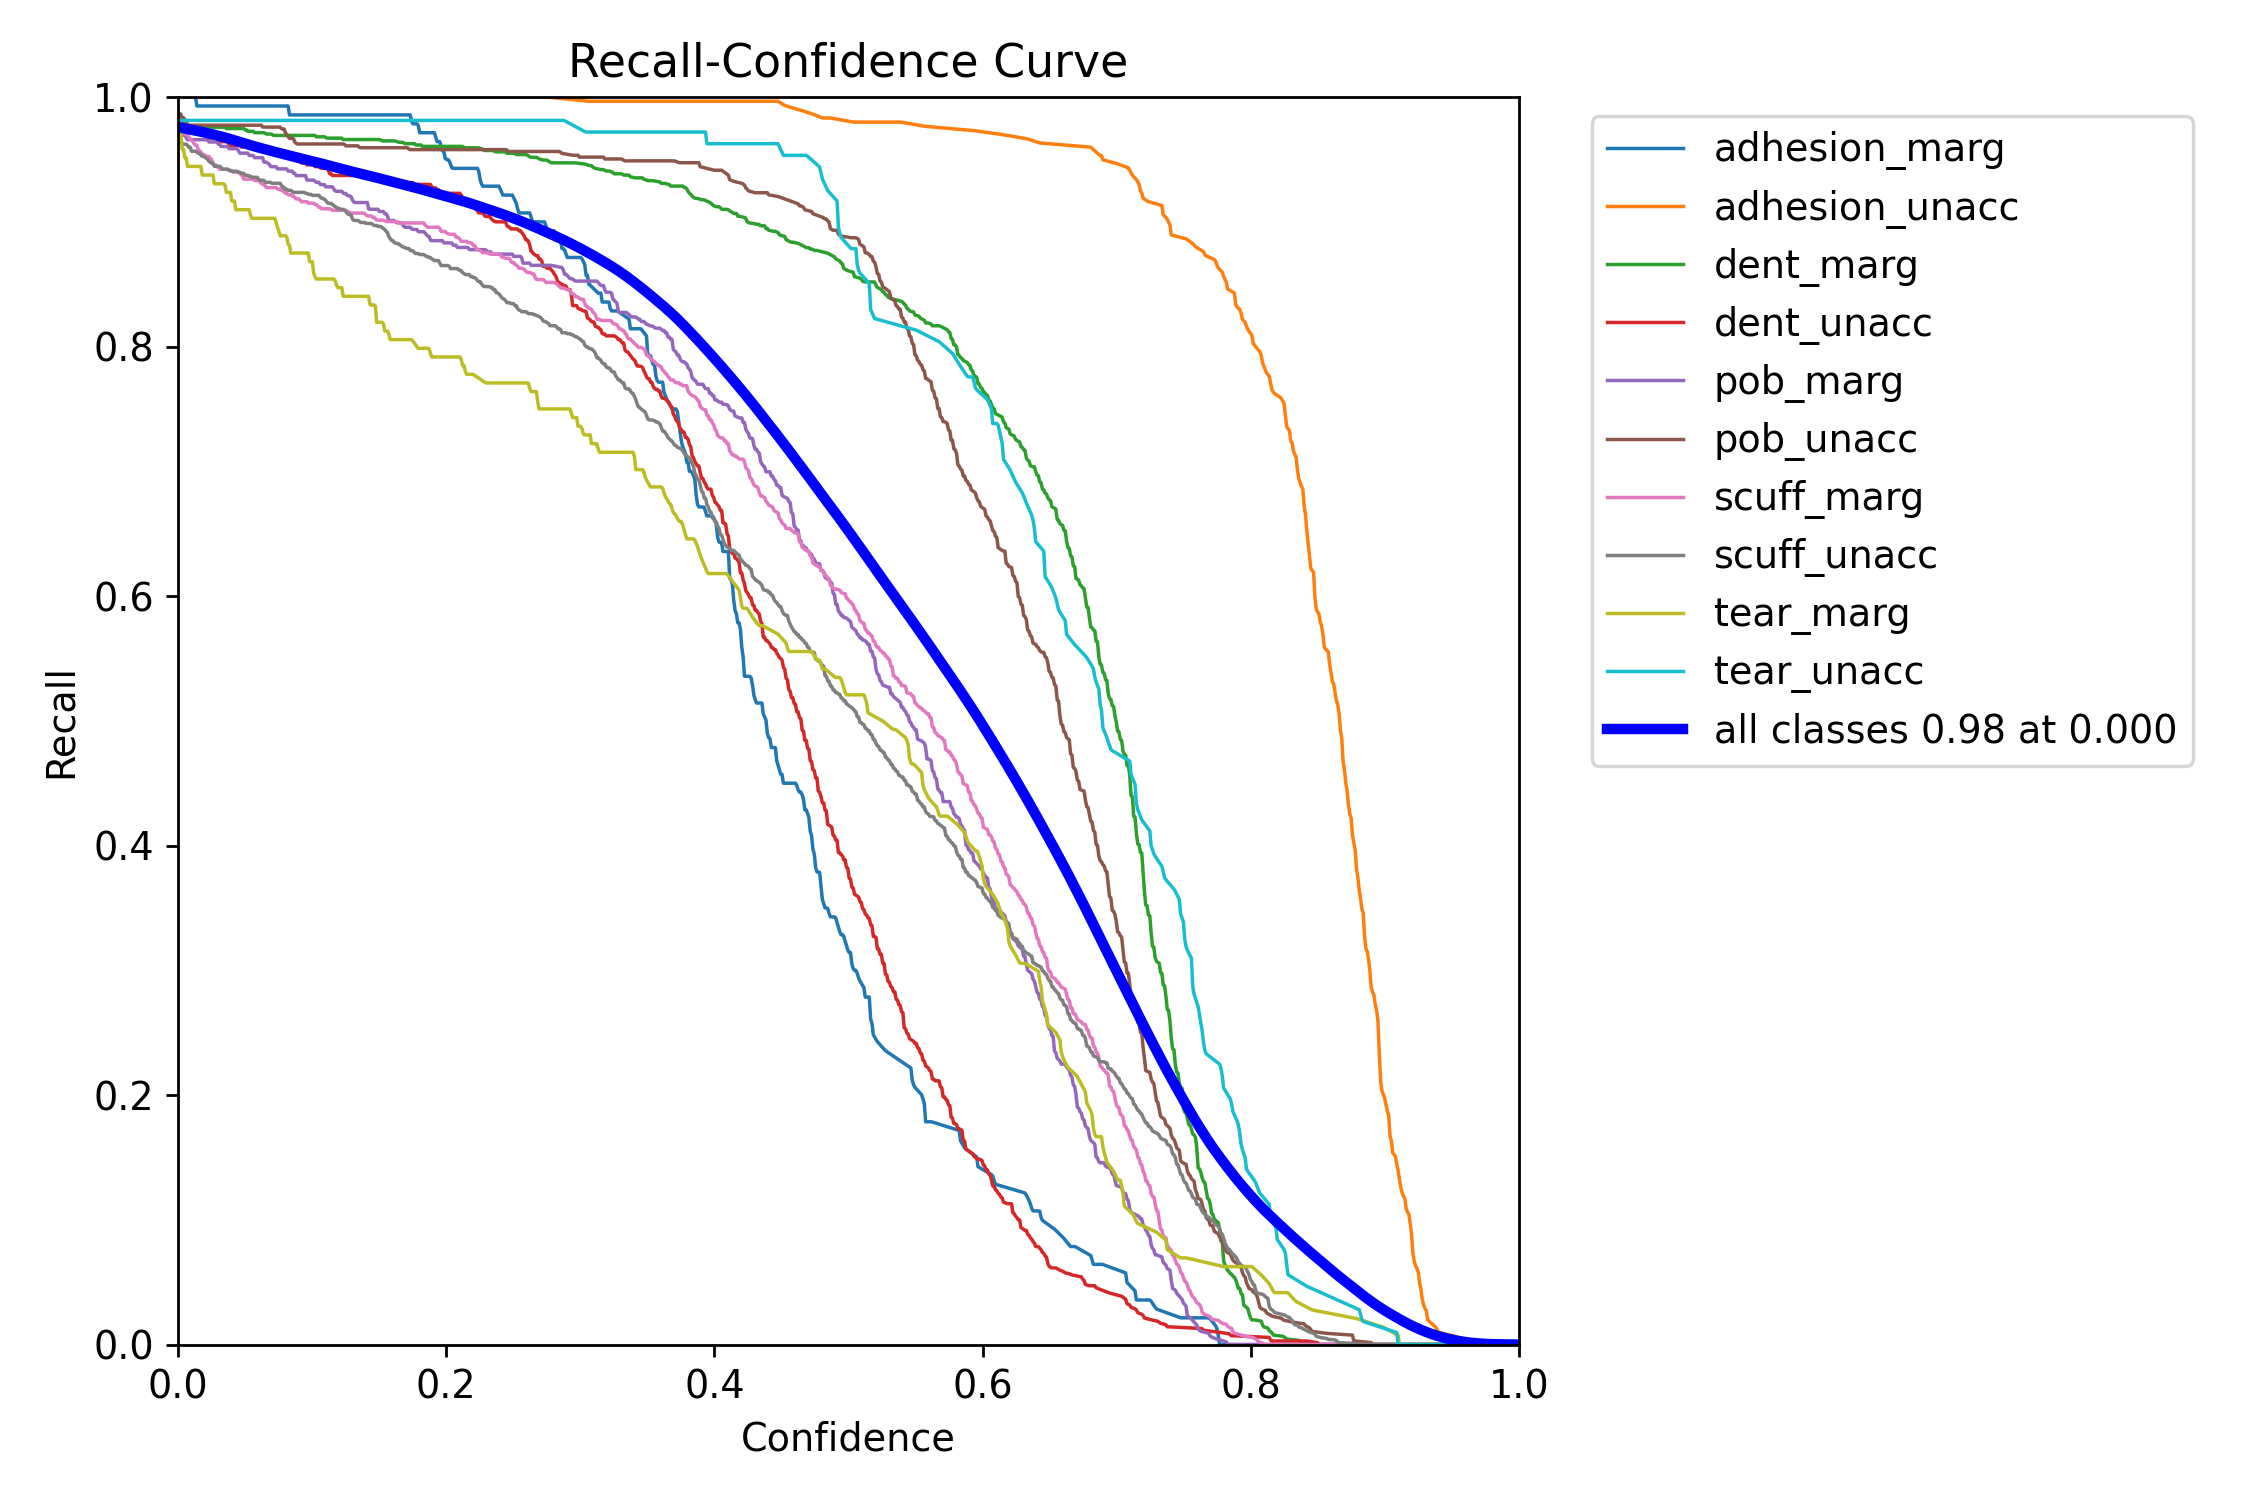

In [1]:
from IPython.display import Image, display
import os

RESULTS_DIR = "/home/f15c/H/runs/detect/YOLO_Experiments/YOLOv8n_Plastic_Shampoo_Bottle"

plots = [
    "results.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "BoxPR_curve.png",
    "BoxF1_curve.png",
    "BoxP_curve.png",
    "BoxR_curve.png"
]

for plot in plots:

    file_path = os.path.join(RESULTS_DIR, plot)

    if os.path.exists(file_path):

        print(plot)

        display(Image(filename=file_path))

In [21]:
import pandas as pd

results_csv = "/home/f15c/H/runs/detect/YOLO_Experiments/YOLOv8n_Plastic_Shampoo_Bottle/results.csv"

df = pd.read_csv(results_csv)

df.tail()

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
95,96,3591.59,1.53517,0.84304,1.15918,0.77719,0.84974,0.84423,0.41987,1.71795,0.89008,1.22806,0.000042,0.000042,0.000042
96,97,3628.07,1.52893,0.83859,1.15506,0.77628,0.85168,0.84339,0.41983,1.71642,0.88802,1.22727,0.000035,0.000035,0.000035
97,98,3664.27,1.52886,0.83895,1.16085,0.77924,0.84922,0.84242,0.42032,1.71425,0.88769,1.22664,0.000028,0.000028,0.000028
98,99,3700.71,1.52334,0.83286,1.15332,0.77639,0.85136,0.84267,0.41939,1.71463,0.88649,1.22696,0.000021,0.000021,0.000021
99,100,3737.19,1.52498,0.83433,1.15321,0.77457,0.85033,0.84319,0.41894,1.71451,0.88631,1.22709,0.000014,0.000014,0.000014


In [22]:
import pandas as pd
best_epoch = df["metrics/mAP50(B)"].idxmax()

best_results = df.loc[best_epoch]

print("Best Epoch:", best_epoch)

print("\nPrecision :", best_results["metrics/precision(B)"])
print("Recall    :", best_results["metrics/recall(B)"])
print("mAP50     :", best_results["metrics/mAP50(B)"])
print("mAP50-95  :", best_results["metrics/mAP50-95(B)"])

Best Epoch: 94

Precision : 0.77861
Recall    : 0.85574
mAP50     : 0.84542
mAP50-95  : 0.42039


In [23]:
precision = best_results["metrics/precision(B)"]
recall = best_results["metrics/recall(B)"]

f1 = 2 * precision * recall / (precision + recall)

print("F1 Score =", round(f1,4))

F1 Score = 0.8154


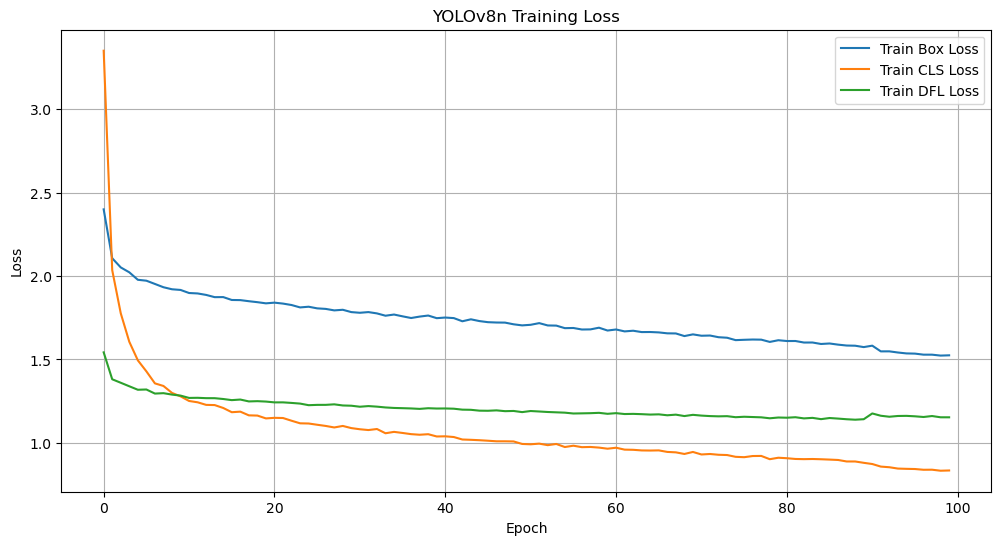

In [25]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(12,6))

plt.plot(df["train/box_loss"], label="Train Box Loss")
plt.plot(df["train/cls_loss"], label="Train CLS Loss")
plt.plot(df["train/dfl_loss"], label="Train DFL Loss")

plt.title("YOLOv8n Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [27]:
from ultralytics import YOLO
from PIL import Image
from IPython.display import display

MODEL_PATH = "/home/f15c/H/runs/detect/YOLO_Experiments/YOLOv8n_Plastic_Shampoo_Bottle/weights/best.pt"

model = YOLO(MODEL_PATH)

image_path = "/home/f15c/H/Plastic_Shampoo_Bottle_Dataset/test/images/marginal-3-_jpg.rf.1c978459945c7981b6b7bdd9f0126683.jpg"  

results = model.predict(
    source=image_path,
    conf=0.25,
    save=True
)




image 1/1 /home/f15c/H/Plastic_Shampoo_Bottle_Dataset/test/images/marginal-3-_jpg.rf.1c978459945c7981b6b7bdd9f0126683.jpg: 640x384 3 adhesion_margs, 22.2ms
Speed: 1.1ms preprocess, 22.2ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 384)
Results saved to /home/f15c/H/runs/detect/predict-4


In [29]:
yolov8_results = {
    "Model":"YOLOv8n",
    "Params":"3.2M",
    "Precision":round(float(precision),4),
    "Recall":round(float(recall),4),
    "F1":round(float(f1),4),
    "mAP50":round(float(best_results["metrics/mAP50(B)"]),4),
    "mAP50-95":round(float(best_results["metrics/mAP50-95(B)"]),4),
    "GFLOPs":"8.7",
    "FPS":"TBD",
    "Training Time":"63.22 minutes"
}

yolov8_results

{'Model': 'YOLOv8n',
 'Params': '3.2M',
 'Precision': 0.7786,
 'Recall': 0.8557,
 'F1': 0.8154,
 'mAP50': 0.8454,
 'mAP50-95': 0.4204,
 'GFLOPs': '8.7',
 'FPS': 'TBD',
 'Training Time': '63.22 minutes'}

In [30]:
yolov8_metadata = {
    
    "Model":"YOLOv8n",

    "Parameters(M)":3.2,

    "GFLOPs":8.7,

    "Training_Time(min)":training_time_v8
}

yolov8_metadata

{'Model': 'YOLOv8n',
 'Parameters(M)': 3.2,
 'GFLOPs': 8.7,
 'Training_Time(min)': 63.21697204510371}

In [31]:
metadata_v8 = pd.DataFrame([yolov8_metadata])

metadata_v8.to_csv(
    os.path.join(
        TABLES_DIR,
        "yolov8_metadata.csv"
    ),
    index=False
)

metadata_v8

,Model,Parameters(M),GFLOPs,Training_Time(min)
0,YOLOv8n,3.2,8.7,63.216972


In [32]:
from ultralytics import YOLO

BEST_MODEL = "/home/f15c/H/runs/detect/YOLO_Experiments/YOLOv8n_Plastic_Shampoo_Bottle/weights/best.pt"

model = YOLO(BEST_MODEL)

test_metrics = model.val(
    data="/home/f15c/H/Plastic_Shampoo_Bottle_Dataset/data.yaml",
    split="test",
    imgsz=640,
    batch=16,
    device=0
)

Ultralytics 8.4.70 🚀 Python-3.12.11 torch-2.8.0+cu129 CUDA:0 (NVIDIA GeForce RTX 2080 SUPER, 7783MiB)
Model summary (fused): 73 layers, 3,007,598 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 19.0±6.1 MB/s, size: 21.5 KB)
val: Scanning /home/f15c/H/Plastic_Shampoo_Bottle_Dataset/test/labels... 790 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 790/790 343.9it/s 2.3s0.0s
val: New cache created: /home/f15c/H/Plastic_Shampoo_Bottle_Dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 50/50 15.7it/s 3.2s0.1s
                   all        790       2920      0.792      0.848       0.86      0.437
         adhesion_marg         46         93      0.693      0.796      0.792      0.409
        adhesion_unacc         85        199      0.934          1      0.975      0.757
             dent_marg        106        387        0.9       0.91      0.943      0.432
        

In [33]:
print("Test Precision :", test_metrics.box.mp)
print("Test Recall    :", test_metrics.box.mr)
print("Test mAP50     :", test_metrics.box.map50)
print("Test mAP50-95  :", test_metrics.box.map)

Test Precision : 0.7922493053395867
Test Recall    : 0.848190796128466
Test mAP50     : 0.8600356595383285
Test mAP50-95  : 0.43718202051849625


In [34]:
precision_test = test_metrics.box.mp
recall_test = test_metrics.box.mr

f1_test = (
    2 * precision_test * recall_test
    / (precision_test + recall_test)
)

print("Test F1 =", round(f1_test,4))

Test F1 = 0.8193
